# REACT tutorial: measuring adaptation speed, not just accuracy

This notebook walks through `reactmetric` end to end on synthetic data:

1. Load trajectories with regime changes.
2. Detect events and fit the reference climatology.
3. Benchmark several forecasters on **REACT**.
4. Contrast REACT with **ADE/FDE** — the motivating story.
5. Inspect **calibration** (call out, never correct).

Everything here runs without any proprietary data.

In [1]:
import warnings
import reactmetric as rm

# 1. Synthetic trajectories with ground-truth regime changes.
data, ground_truth_events = rm.datasets.synthetic_regime_changes(n=300, seed=0)
calib, test = data.split(fraction=0.25, seed=0)
print(data)

TrajectorySet(n=300, D=2, dt=0.1)


## 2. Detect events and fit the reference

The reference is the *climatology* — what you'd expect knowing only population statistics. REACT measures how fast a forecast beats it again after a disruption.

In [2]:
detector = rm.events.KinematicChangepoints()
ref = rm.reference.Climatology.fit(calib, leads=(1, 5, 10, 15), mode="kinematic")
ref.metadata()["per_lead"]["10"]["differential_entropy_gaussian_nats"]

0.9260662975225262

## 3. Benchmark forecasters on REACT

In [3]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    report = rm.benchmark(
        forecasts={"IMM": rm.baselines.IMM()},
        data=test, calibration=calib,
        baselines=["ConstantVelocity", "CTRV"],
        oracle="C", events=detector, lead=10,
    )
report.table()

,n_events,anticipation_rate,failure_rate,superseded_rate,km_median_react,mean_react_uncensored,mean_excess_react,steady_state_mean_info,steady_state_frac_informative
model,,,,,,,,,
IMM,415,0.296386,0.286747,0.192771,31.0,14.756757,8.690720,-0.097593,0.348797
ConstantVelocity,415,0.142169,0.250602,0.233735,12.0,11.270096,5.381741,-3.975594,0.709622
CTRV,415,0.253012,0.228916,0.219277,14.0,8.515625,2.706038,-0.088786,0.780069


## 4. The motivating story: ADE/FDE vs REACT

Two models can have nearly identical average accuracy yet very different adaptation speed. That gap is exactly what REACT exposes.

In [4]:
models = {
    "ConstantVelocity": rm.baselines.ConstantVelocity(),
    "CTRV": rm.baselines.CTRV(),
    "IMM": rm.baselines.IMM(),
}
acc = rm.forecast_accuracy(models, test, leads=(1, 5, 10, 15))
for name, a in acc.items():
    res = report.results[name]
    print(f"{name:18s} ADE={a['ade_m']:.3f}m  KM-median REACT={res.km_median():.1f} frames")

ConstantVelocity   ADE=0.243m  KM-median REACT=12.0 frames
CTRV               ADE=0.299m  KM-median REACT=14.0 frames
IMM                ADE=0.245m  KM-median REACT=31.0 frames


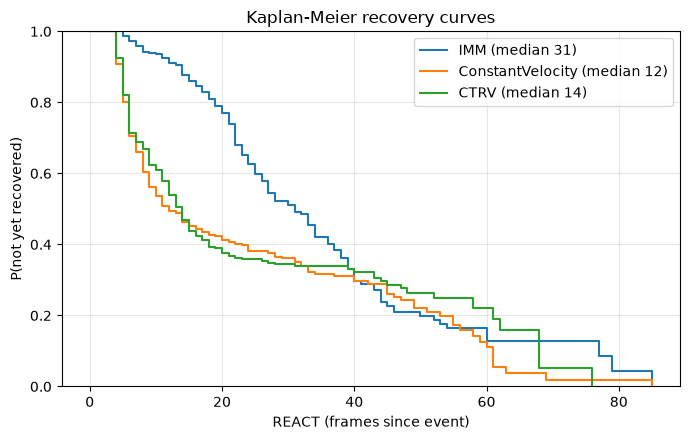

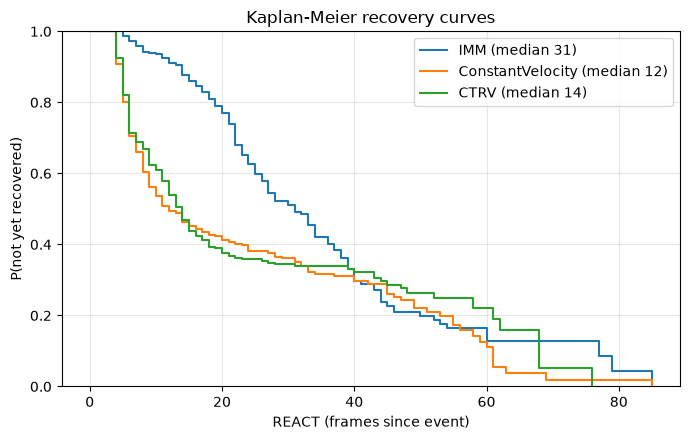

In [5]:
# Kaplan-Meier recovery curves (requires reactmetric[viz])
report.plot_km()

## 5. Calibration: call out, never correct

REACT scores the forecast *as delivered*. The calibration report tells you *why* a model is slow (e.g. it is overconfident) but never silently rescales it. The opt-in counterfactual answers the separate "what if I rescaled my covariances?" question.

In [6]:
overconfident = rm.baselines.ConstantVelocity(measurement_noise=0.005, name="Overconfident")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rep = rm.calibration.report(overconfident, data, ref, ground_truth_events, lead=10,
                                emit_warning=False)
print(rep.summary())

Calibration report for 'Overconfident' [MISCALIBRATED]
  samples: 300  dim: 2
  coverage chi2 (mean Mahalanobis^2): 360.633  (calibrated = 2; ratio 180.32)
  PIT KS p-values per axis: [0.000, 0.000]
  mean bias per axis: [+0.004, -0.001]
  sharpness (mean 0.5*logdet): -9.803 nats
  scalar-temperature (counterfactual only): 180.317
  ! OVERCONFIDENT: mean Mahalanobis^2 = 360.63 >> D = 2 (covariances ~180.3x too small). REACT will (correctly) penalize this; see calibration.counterfactual_react for the scalar-calibrated counterfactual.
  ! axis 0: PIT is non-uniform (KS p=2.29e-66); shape miscalibration.
  ! axis 1: PIT is non-uniform (KS p=1.21e-49); shape miscalibration.


In [7]:
# The opt-in counterfactual: what REACT WOULD be if covariances were rescaled.
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    cf = rm.calibration.counterfactual_react(overconfident, test, ref, ground_truth_events, lead=10)
print(cf.summary())

Counterfactual scalar recalibration (T=219.500) -- HYPOTHETICAL:
  anticipation  delivered 0.000 -> recalibrated 0.103
  failure       delivered 1.000 -> recalibrated 0.118
  KM median     delivered nan -> recalibrated 9.0 frames
  NOTE: this rescales covariances and scores a different forecast than the one you delivered; not the headline REACT.
